In [3]:
import pandas as pd

data = {
    "Name": ["Anu", "Rahul", "Priya", "Amit", "Sneha",
             "Karan", "Riya", "Arjun", "Neha", "Vikram"],
    "Age": [21, 25, 22, 28, 24, 30, 26, 23, 27, 29],
    "Gender": ["F", "M", "F", "M", "F", "M", "F", "M", "F", "M"],
    "Marks": [85, 72, 91, 65, 88, 76, 95, 69, 82, 78],
    "City": ["Kolkata", "Delhi", "Mumbai", "Delhi", "Kolkata",
             "Mumbai", "Delhi", "Kolkata", "Mumbai", "Delhi"]
}

df = pd.DataFrame(data)

print(df)


     Name  Age Gender  Marks     City
0     Anu   21      F     85  Kolkata
1   Rahul   25      M     72    Delhi
2   Priya   22      F     91   Mumbai
3    Amit   28      M     65    Delhi
4   Sneha   24      F     88  Kolkata
5   Karan   30      M     76   Mumbai
6    Riya   26      F     95    Delhi
7   Arjun   23      M     69  Kolkata
8    Neha   27      F     82   Mumbai
9  Vikram   29      M     78    Delhi


In [3]:
#Exercises
#1. Basic inspection
#1. Display the first 5 rows.
df.head()

,Name,Age,Gender,Marks,City
0,Anu,21,F,85,Kolkata
1,Rahul,25,M,72,Delhi
2,Priya,22,F,91,Mumbai
3,Amit,28,M,65,Delhi
4,Sneha,24,F,88,Kolkata


In [4]:
#2. Display the last 3 rows.

df.tail(3)

,Name,Age,Gender,Marks,City
7,Arjun,23,M,69,Kolkata
8,Neha,27,F,82,Mumbai
9,Vikram,29,M,78,Delhi


In [8]:
#3. Find the number of rows and columns.
len(df)
df.shape

(10, 5)

In [10]:
#4. Find the column names.
df.columns
df.index

RangeIndex(start=0, stop=10, step=1)

In [13]:
#5. Find the data types.
df.dtype

Name      object
Age        int64
Gender    object
Marks      int64
City      object
dtype: object

In [14]:
#6. Use describe().
df.describe()

,Age,Marks
count,10.00000,10.000000
mean,25.50000,80.100000
std,3.02765,9.825703
min,21.00000,65.000000
25%,23.25000,73.000000
50%,25.50000,80.000000
75%,27.75000,87.250000
max,30.00000,95.000000


In [19]:
#LEVEL 2 — Selecting & Filtering
#7. Display only Name and Marks.
df[["Name","Marks"]]

,Name,Marks
0,Anu,85
1,Rahul,72
2,Priya,91
3,Amit,65
4,Sneha,88
5,Karan,76
6,Riya,95
7,Arjun,69
8,Neha,82
9,Vikram,78


In [34]:
#8. Display students whose marks are greater than 80.
df[df["Marks"]>80].reset_index(drop=True).Name


0      Anu
1    Priya
2    Sneha
3     Riya
4     Neha
Name: Name, dtype: object

In [39]:
#7. Display students whose age is greater than 25.
df[df["Age"]>25].reset_index(drop=True).Name




0      Amit
1     Karan
2      Riya
3      Neha
4    Vikram
Name: Name, dtype: object

In [42]:
#8. Find students from Kolkata.
df[df["City"]=="Kolkata"].reset_index(drop=False).Name


0      Anu
1    Sneha
2    Arjun
Name: Name, dtype: object

In [47]:
#9. Find students from Delhi and having marks > 70.
city=df["City"]=="Delhi"
marks=df["Marks"]>70
df[(city&marks)].Name


1     Rahul
6      Riya
9    Vikram
Name: Name, dtype: object

In [48]:
#10. Find students whose marks are between 70 and 90.
df[df["Marks"].between(70,90)].reset_index(drop=True).Name

0       Anu
1     Rahul
2     Sneha
3     Karan
4      Neha
5    Vikram
Name: Name, dtype: object

In [51]:
#11. Find students whose city is either Kolkata or Mumbai.
city1=df["City"]=="Kolkata"
city2=df["City"]=="Mumbai"
df[(city1|city2)].reset_index(drop=True).Name

0      Anu
1    Priya
2    Sneha
3    Karan
4    Arjun
5     Neha
Name: Name, dtype: object

In [56]:
#12. Find the student with the highest marks.
df[df["Marks"]==df["Marks"].max()].Name


6    Riya
Name: Name, dtype: object

In [59]:
#13. Find the student with the lowest marks.
df[df["Marks"]==df["Marks"].min()].Name
df.loc[df["Marks"].idxmax(),"Name"]

'Riya'

In [64]:
# Pass = Yes if Marks >= 40 No otherwise
import numpy as np
df["Pass"]=np.where(df["Marks"]>=70,"Yes","No")
df

,Name,Age,Gender,Marks,City,Pass
0,Anu,21,F,85,Kolkata,Yes
1,Rahul,25,M,72,Delhi,Yes
2,Priya,22,F,91,Mumbai,Yes
3,Amit,28,M,65,Delhi,No
4,Sneha,24,F,88,Kolkata,Yes
5,Karan,30,M,76,Mumbai,Yes
6,Riya,26,F,95,Delhi,Yes
7,Arjun,23,M,69,Kolkata,No
8,Neha,27,F,82,Mumbai,Yes
9,Vikram,29,M,78,Delhi,Yes


In [79]:
#Age < 25       → Young
#25–27          → Adult
#>27            → Senior
#df["Age_Group"]=np.where(df["Age"]<25,"Young",np.where(df["Age"].between(25,27),"Adult","Senior"))
#def Age_Group(x):
   # if x<25:
       # return  "Young"
   # elif 25<=x<=27:
      #  return  "Adult"
   # else:
      #  return "Senior"
#df["Age_Group"]=df["Age"].apply(Age_Group)
#
import numpy as np
conditions=[df["Age"]<25, df["Age"].between(25,27),df["Age"]>27]
choices=["Young","Adult","Senior"]
df["Age_Group"]=np.select(conditions,choices,default="Unknown")
df

,Name,Age,Gender,Marks,City,Pass,Age_Group
0,Anu,21,F,85,Kolkata,Yes,Young
1,Rahul,25,M,72,Delhi,Yes,Adult
2,Priya,22,F,91,Mumbai,Yes,Young
3,Amit,28,M,65,Delhi,No,Senior
4,Sneha,24,F,88,Kolkata,Yes,Young
5,Karan,30,M,76,Mumbai,Yes,Senior
6,Riya,26,F,95,Delhi,Yes,Adult
7,Arjun,23,M,69,Kolkata,No,Young
8,Neha,27,F,82,Mumbai,Yes,Adult
9,Vikram,29,M,78,Delhi,Yes,Senior


In [80]:
#Marks_10 = Marks / 10
df["Marks_10"]=df["Marks"]/10
df

,Name,Age,Gender,Marks,City,Pass,Age_Group,Marks_10
0,Anu,21,F,85,Kolkata,Yes,Young,8.5
1,Rahul,25,M,72,Delhi,Yes,Adult,7.2
2,Priya,22,F,91,Mumbai,Yes,Young,9.1
3,Amit,28,M,65,Delhi,No,Senior,6.5
4,Sneha,24,F,88,Kolkata,Yes,Young,8.8
5,Karan,30,M,76,Mumbai,Yes,Senior,7.6
6,Riya,26,F,95,Delhi,Yes,Adult,9.5
7,Arjun,23,M,69,Kolkata,No,Young,6.9
8,Neha,27,F,82,Mumbai,Yes,Adult,8.2
9,Vikram,29,M,78,Delhi,Yes,Senior,7.8


In [81]:
# Excellent → Marks >= 90 Good      → 75–89 Average   → 60–74 Needs Work → <60
df["Grade"]=np.where(df["Marks"]>=90,"Exceelent",np.where(df["Marks"].between(75,89),"Good",np.where(df["Marks"].between(60,74),"Average","Needs Work")))
df

,Name,Age,Gender,Marks,City,Pass,Age_Group,Marks_10,Grade
0,Anu,21,F,85,Kolkata,Yes,Young,8.5,Good
1,Rahul,25,M,72,Delhi,Yes,Adult,7.2,Average
2,Priya,22,F,91,Mumbai,Yes,Young,9.1,Exceelent
3,Amit,28,M,65,Delhi,No,Senior,6.5,Average
4,Sneha,24,F,88,Kolkata,Yes,Young,8.8,Good
5,Karan,30,M,76,Mumbai,Yes,Senior,7.6,Good
6,Riya,26,F,95,Delhi,Yes,Adult,9.5,Exceelent
7,Arjun,23,M,69,Kolkata,No,Young,6.9,Average
8,Neha,27,F,82,Mumbai,Yes,Adult,8.2,Good
9,Vikram,29,M,78,Delhi,Yes,Senior,7.8,Good


In [85]:
# Calculate the mean age.
df["Age"].mean()
# print(df["Age"].mean())

np.float64(25.5)

In [86]:
# Calculate the median age.
df["Age"].median()

25.5

In [87]:
# Calculate the mean marks.
df["Marks"].mean()

np.float64(80.1)

In [88]:
# Calculate the median marks.
df["Marks"].median()

80.0

In [94]:
#Find Q1 of marks.#Find Q3 of marks.
#Calculate IQR.

df["Marks"].quantile([.25,.75])
Q1=df["Marks"].quantile(.25)
Q3=df["Marks"].quantile(.75)
Q3-Q1

np.float64(14.25)

In [100]:
# Find the standard deviation of marks.
#Find the variance.
standarddev=df["Marks"].std()
variance=standarddev**2
print(variance,standarddev)

96.54444444444445 9.8257032544467


In [103]:
# Calculate the skewness of the Marks column.
skewness=df["Marks"].skew()
print(skewness)

-0.02923554134220031


In [107]:
# correlation between age and marks 
print(df["Age"].corr(df["Marks"]))

-0.34922050657537196


In [113]:
# 32. Sort students by marks ascending.
df.sort_values( "Marks",ascending=True)
df.sort_values("Marks",ascending=False)

,Name,Age,Gender,Marks,City,Pass,Age_Group,Marks_10,Grade
6,Riya,26,F,95,Delhi,Yes,Adult,9.5,Exceelent
2,Priya,22,F,91,Mumbai,Yes,Young,9.1,Exceelent
4,Sneha,24,F,88,Kolkata,Yes,Young,8.8,Good
0,Anu,21,F,85,Kolkata,Yes,Young,8.5,Good
8,Neha,27,F,82,Mumbai,Yes,Adult,8.2,Good
9,Vikram,29,M,78,Delhi,Yes,Senior,7.8,Good
5,Karan,30,M,76,Mumbai,Yes,Senior,7.6,Good
1,Rahul,25,M,72,Delhi,Yes,Adult,7.2,Average
7,Arjun,23,M,69,Kolkata,No,Young,6.9,Average
3,Amit,28,M,65,Delhi,No,Senior,6.5,Average


In [114]:
# 34. Sort by City and then Marks.
df.sort_values(["City","Marks"],ascending=[True,True])


,Name,Age,Gender,Marks,City,Pass,Age_Group,Marks_10,Grade
3,Amit,28,M,65,Delhi,No,Senior,6.5,Average
1,Rahul,25,M,72,Delhi,Yes,Adult,7.2,Average
9,Vikram,29,M,78,Delhi,Yes,Senior,7.8,Good
6,Riya,26,F,95,Delhi,Yes,Adult,9.5,Exceelent
7,Arjun,23,M,69,Kolkata,No,Young,6.9,Average
0,Anu,21,F,85,Kolkata,Yes,Young,8.5,Good
4,Sneha,24,F,88,Kolkata,Yes,Young,8.8,Good
5,Karan,30,M,76,Mumbai,Yes,Senior,7.6,Good
8,Neha,27,F,82,Mumbai,Yes,Adult,8.2,Good
2,Priya,22,F,91,Mumbai,Yes,Young,9.1,Exceelent


In [116]:
# 34. Sort by City and then Marks.
df.sort_values(["City","Marks"],ascending=[False,False])

,Name,Age,Gender,Marks,City,Pass,Age_Group,Marks_10,Grade
2,Priya,22,F,91,Mumbai,Yes,Young,9.1,Exceelent
8,Neha,27,F,82,Mumbai,Yes,Adult,8.2,Good
5,Karan,30,M,76,Mumbai,Yes,Senior,7.6,Good
4,Sneha,24,F,88,Kolkata,Yes,Young,8.8,Good
0,Anu,21,F,85,Kolkata,Yes,Young,8.5,Good
7,Arjun,23,M,69,Kolkata,No,Young,6.9,Average
6,Riya,26,F,95,Delhi,Yes,Adult,9.5,Exceelent
9,Vikram,29,M,78,Delhi,Yes,Senior,7.8,Good
1,Rahul,25,M,72,Delhi,Yes,Adult,7.2,Average
3,Amit,28,M,65,Delhi,No,Senior,6.5,Average


In [120]:
# 35. Display the top 3 students.
A=df.sort_values("Marks",ascending=False).reset_index(drop=True)
A.head(3)

,Name,Age,Gender,Marks,City,Pass,Age_Group,Marks_10,Grade
0,Riya,26,F,95,Delhi,Yes,Adult,9.5,Exceelent
1,Priya,22,F,91,Mumbai,Yes,Young,9.1,Exceelent
2,Sneha,24,F,88,Kolkata,Yes,Young,8.8,Good


In [121]:
#🟡 LEVEL 6 — value_counts()
# 37. Count how many students are from each city.
df["City"].value_counts()

City
Delhi      4
Kolkata    3
Mumbai     3
Name: count, dtype: int64

In [122]:
#38. Count how many males and females there are.
df["Gender"].value_counts()

Gender
F    5
M    5
Name: count, dtype: int64

In [123]:
# 39. Count how many students belong to each Age_Group.
df["Age_Group"].value_counts()

Age_Group
Young     4
Adult     3
Senior    3
Name: count, dtype: int64

In [135]:
# 40. Find the most common city.
df["City"].value_counts().head(1)
df["City"].value_counts().idxmax()

'Delhi'

In [138]:
#🟠 LEVEL 7 — GROUPBY
# This is very important.
# 41. Find average marks by city.
df.groupby("City")["Marks"].mean()

City
Delhi      77.500000
Kolkata    80.666667
Mumbai     83.000000
Name: Marks, dtype: float64

In [139]:
#42. Find maximum marks by city.
df.groupby("City")["Marks"].max()


City
Delhi      95
Kolkata    88
Mumbai     91
Name: Marks, dtype: int64

In [140]:
# 43. Find minimum marks by city.
df.groupby("City")["Marks"].min()


City
Delhi      65
Kolkata    69
Mumbai     76
Name: Marks, dtype: int64

In [146]:
#44. Find number of students in each city.
df.groupby("City")["Marks"].count()
# df["City"].value_counts()

City
Delhi      4
Kolkata    3
Mumbai     3
Name: Marks, dtype: int64

In [147]:
# 41. Find average age by gender.
df.groupby("Gender")["Age"].mean()

Gender
F    24.0
M    27.0
Name: Age, dtype: float64

In [148]:
# 42. Find average marks by gender.
df.groupby("Gender")["Marks"].mean()

Gender
F    88.2
M    72.0
Name: Marks, dtype: float64

In [149]:
# 43. Find average marks by city and gender.
df.groupby(["City","Gender"])["Marks"].mean()

City     Gender
Delhi    F         95.000000
         M         71.666667
Kolkata  F         86.500000
         M         69.000000
Mumbai   F         86.500000
         M         76.000000
Name: Marks, dtype: float64

In [152]:
# 44. Find the maximum marks obtained in each city.
df.groupby("City")["Marks"].max()

City
Delhi      95
Kolkata    88
Mumbai     91
Name: Marks, dtype: int64

In [155]:
# 45. Find the student count and average marks for each city.
df.groupby("City")["Marks"].agg(["count","mean"])

,count,mean
City,,
Delhi,4,77.500000
Kolkata,3,80.666667
Mumbai,3,83.000000


In [158]:
# crosstab=City × Gender
d1=df["City"]
d2=df["Gender"]
pd.crosstab(d1,d2)
pd.crosstab(d2,d1)

City,Delhi,Kolkata,Mumbai
Gender,,,
F,1,2,2
M,3,1,1


In [164]:
# pivot table=City → average Marks
pivot=pd.pivot_table(df,index="City",values="Marks",aggfunc="mean")
pivot

,Marks
City,
Delhi,77.500000
Kolkata,80.666667
Mumbai,83.000000


In [169]:
# City × Gender → average Marks
pivot=pd.pivot_table(df,index="City",columns="Gender",values="Marks",aggfunc="mean")
pivot

Gender,F,M
City,,
Delhi,95.0,71.666667
Kolkata,86.5,69.000000
Mumbai,86.5,76.000000


In [173]:
# City × Gender → number of students
pivot=pd.pivot_table(df,index="City",columns="Gender",values="Marks",aggfunc="count")
pivot


Gender,F,M
City,,
Delhi,1,3
Kolkata,2,1
Mumbai,2,1


In [179]:

pivot=pd.pivot_table(df,index="City",values="Marks",aggfunc=(["mean","max","min"]))
pivot=pivot.swaplevel(axis=1).sort_index(axis=1)
pivot

Marks               
          max       mean min
City                        
Delhi      95  77.500000  65
Kolkata    88  80.666667  69
Mumbai     91  83.000000  76

In [183]:
df.loc[2, "Marks"] = None
df.loc[5, "Age"] = None
df.loc[7, "City"] = None
df
# Find all missing values.
df.isna().any()



Name         False
Age           True
Gender       False
Marks         True
City          True
Pass         False
Age_Group    False
Marks_10     False
Grade        False
dtype: bool

In [184]:
# Count missing values in each column.
df.isna().sum()


Name         0
Age          1
Gender       0
Marks        1
City         1
Pass         0
Age_Group    0
Marks_10     0
Grade        0
dtype: int64

In [185]:
#Find rows containing missing values.
df.isna().sum(axis=1)

0    0
1    0
2    1
3    0
4    0
5    1
6    0
7    1
8    0
9    0
dtype: int64

In [214]:
#Remove rows containing missing values.
df=df.dropna(how="all",axis=1)
df


,Name,Age,Gender,Marks,City,Pass,Age_Group,Marks_10,Grade
0,Anu,21.0,F,85.000000,Kolkata,Yes,Young,8.5,Good
1,Rahul,25.0,M,72.000000,Delhi,Yes,Adult,7.2,Average
2,Priya,22.0,F,78.888889,Mumbai,Yes,Young,9.1,Exceelent
3,Amit,28.0,M,65.000000,Delhi,No,Senior,6.5,Average
4,Sneha,24.0,F,88.000000,Kolkata,Yes,Young,8.8,Good
5,Karan,25.0,M,76.000000,Mumbai,Yes,Senior,7.6,Good
6,Riya,26.0,F,95.000000,Delhi,Yes,Adult,9.5,Exceelent
7,Arjun,23.0,M,69.000000,Unknown,No,Young,6.9,Average
8,Neha,27.0,F,82.000000,Mumbai,Yes,Adult,8.2,Good
9,Vikram,29.0,M,78.000000,Delhi,Yes,Senior,7.8,Good


In [196]:
#Fill missing Marks with the mean.
df["Marks"].mean()
df["Marks"]=df["Marks"].fillna(df["Marks"].mean())
df
#Fill missing Age with the median.
df["Age"]=df["Age"].fillna(df["Age"].median())
df
#Fill missing City with "Unknown".
df["City"]=df["City"].fillna("Unknown")
df
#Compare the dataset before and after cleaning.
# use compare word nd also save the original dataframe then compare their shapes size nd also the isna() fillna() nd all

,Name,Age,Gender,Marks,City,Pass,Age_Group,Marks_10,Grade
0,Anu,21.0,F,85.000000,Kolkata,Yes,Young,8.5,Good
1,Rahul,25.0,M,72.000000,Delhi,Yes,Adult,7.2,Average
2,Priya,22.0,F,78.888889,Mumbai,Yes,Young,9.1,Exceelent
3,Amit,28.0,M,65.000000,Delhi,No,Senior,6.5,Average
4,Sneha,24.0,F,88.000000,Kolkata,Yes,Young,8.8,Good
5,Karan,25.0,M,76.000000,Mumbai,Yes,Senior,7.6,Good
6,Riya,26.0,F,95.000000,Delhi,Yes,Adult,9.5,Exceelent
7,Arjun,23.0,M,69.000000,Unknown,No,Young,6.9,Average
8,Neha,27.0,F,82.000000,Mumbai,Yes,Adult,8.2,Good
9,Vikram,29.0,M,78.000000,Delhi,Yes,Senior,7.8,Good


In [206]:
df = pd.concat([df, df.iloc[[2]]])
df_original=df.copy()
# 63. Detect duplicate rows.
df.duplicated()
df_original
# 69. Find unique values in each categorical column.

,Name,Age,Gender,Marks,City,Pass,Age_Group,Marks_10,Grade
0,Anu,21.0,F,85.000000,Kolkata,Yes,Young,8.5,Good
1,Rahul,25.0,M,72.000000,Delhi,Yes,Adult,7.2,Average
2,Priya,22.0,F,78.888889,Mumbai,Yes,Young,9.1,Exceelent
3,Amit,28.0,M,65.000000,Delhi,No,Senior,6.5,Average
4,Sneha,24.0,F,88.000000,Kolkata,Yes,Young,8.8,Good
5,Karan,25.0,M,76.000000,Mumbai,Yes,Senior,7.6,Good
6,Riya,26.0,F,95.000000,Delhi,Yes,Adult,9.5,Exceelent
7,Arjun,23.0,M,69.000000,Unknown,No,Young,6.9,Average
8,Neha,27.0,F,82.000000,Mumbai,Yes,Adult,8.2,Good
9,Vikram,29.0,M,78.000000,Delhi,Yes,Senior,7.8,Good


In [209]:
# 64. Count duplicates.
print(df.duplicated().sum())

3


In [215]:
# 65. Remove duplicates.
df=df.drop_duplicates()
df

,Name,Age,Gender,Marks,City,Pass,Age_Group,Marks_10,Grade
0,Anu,21.0,F,85.000000,Kolkata,Yes,Young,8.5,Good
1,Rahul,25.0,M,72.000000,Delhi,Yes,Adult,7.2,Average
2,Priya,22.0,F,78.888889,Mumbai,Yes,Young,9.1,Exceelent
3,Amit,28.0,M,65.000000,Delhi,No,Senior,6.5,Average
4,Sneha,24.0,F,88.000000,Kolkata,Yes,Young,8.8,Good
5,Karan,25.0,M,76.000000,Mumbai,Yes,Senior,7.6,Good
6,Riya,26.0,F,95.000000,Delhi,Yes,Adult,9.5,Exceelent
7,Arjun,23.0,M,69.000000,Unknown,No,Young,6.9,Average
8,Neha,27.0,F,82.000000,Mumbai,Yes,Adult,8.2,Good
9,Vikram,29.0,M,78.000000,Delhi,Yes,Senior,7.8,Good


In [217]:
# 67. Rename a column.
df.rename(columns={"Marks_10":"CGPA"},inplace=True)
df
# 68. Convert a column to another datatype.
# 69. Find unique values in each categorical column.

C:\Users\singh\AppData\Local\Temp\ipykernel_28072\527186756.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df.rename(columns={"Marks_10":"CGPA"},inplace=True)


,Name,Age,Gender,Marks,City,Pass,Age_Group,CGPA,Grade
0,Anu,21.0,F,85.000000,Kolkata,Yes,Young,8.5,Good
1,Rahul,25.0,M,72.000000,Delhi,Yes,Adult,7.2,Average
2,Priya,22.0,F,78.888889,Mumbai,Yes,Young,9.1,Exceelent
3,Amit,28.0,M,65.000000,Delhi,No,Senior,6.5,Average
4,Sneha,24.0,F,88.000000,Kolkata,Yes,Young,8.8,Good
5,Karan,25.0,M,76.000000,Mumbai,Yes,Senior,7.6,Good
6,Riya,26.0,F,95.000000,Delhi,Yes,Adult,9.5,Exceelent
7,Arjun,23.0,M,69.000000,Unknown,No,Young,6.9,Average
8,Neha,27.0,F,82.000000,Mumbai,Yes,Adult,8.2,Good
9,Vikram,29.0,M,78.000000,Delhi,Yes,Senior,7.8,Good


In [220]:
# 68. Convert a column to another datatype.
df["Grade"]=df["Grade"].astype("category")
df.dtypes

C:\Users\singh\AppData\Local\Temp\ipykernel_28072\1117086897.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["Grade"]=df["Grade"].astype("category")


Name           object
Age           float64
Gender         object
Marks         float64
City           object
Pass           object
Age_Group      object
CGPA          float64
Grade        category
dtype: object

In [222]:
# 69. Find unique values in each categorical columns
categorical_columns=df.select_dtypes(include=["object","category"]).columns
categorical_columns

Index(['Name', 'Gender', 'City', 'Pass', 'Age_Group', 'Grade'], dtype='object')

In [225]:
for col in categorical_columns:
    print(col,":",df[col].unique())

Name : ['Anu' 'Rahul' 'Priya' 'Amit' 'Sneha' 'Karan' 'Riya' 'Arjun' 'Neha'
 'Vikram']
Gender : ['F' 'M']
City : ['Kolkata' 'Delhi' 'Mumbai' 'Unknown']
Pass : ['Yes' 'No']
Age_Group : ['Young' 'Adult' 'Senior']
Grade : ['Good', 'Average', 'Exceelent']
Categories (3, object): ['Average', 'Exceelent', 'Good']


In [243]:
# Convert names to uppercase.
df["Name"].str.upper()
#Convert names to lowercase.
df["Name"].str.lower()
#Find names containing "a".
df[df['Name'].str.contains("a",na=False)]
#Find names starting with "A".
df[df["Name"].str.contains("A",na=False)]
#Find length of each name.
df["Name"].str.len()
df["name_length"]=df["Name"].str.len()
df["name_length"]
df
#Replace a particular character in names.
df["Grade"]=df["Grade"].replace({"Exceelent":"Excellent"})
df

C:\Users\singh\AppData\Local\Temp\ipykernel_28072\4189874665.py:11: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["name_length"]=df["Name"].str.len()
C:\Users\singh\AppData\Local\Temp\ipykernel_28072\4189874665.py:15: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["Grade"]=df["Grade"].replace({"Exceelent":"Excellent"})


,Name,Age,Gender,Marks,City,Pass,Age_Group,CGPA,Grade,name_length
0,Anu,21.0,F,85.000000,Kolkata,Yes,Young,8.5,Good,3
1,Rahul,25.0,M,72.000000,Delhi,Yes,Adult,7.2,Average,5
2,Priya,22.0,F,78.888889,Mumbai,Yes,Young,9.1,Excellent,5
3,Amit,28.0,M,65.000000,Delhi,No,Senior,6.5,Average,4
4,Sneha,24.0,F,88.000000,Kolkata,Yes,Young,8.8,Good,5
5,Karan,25.0,M,76.000000,Mumbai,Yes,Senior,7.6,Good,5
6,Riya,26.0,F,95.000000,Delhi,Yes,Adult,9.5,Excellent,4
7,Arjun,23.0,M,69.000000,Unknown,No,Young,6.9,Average,5
8,Neha,27.0,F,82.000000,Mumbai,Yes,Adult,8.2,Good,4
9,Vikram,29.0,M,78.000000,Delhi,Yes,Senior,7.8,Good,6


In [254]:
fees = pd.DataFrame({
    "Name": ["Anu", "Rahul", "Priya", "Amit"],
    "Fees": [50000, 45000, 55000, 40000]
})

#Perform an inner merge.
A=df.merge(fees,how="inner",on="Name")

#Perform a left merge.
B=df.merge(fees,how="left",on="Name")

#Perform a right merge.
C=df.merge(fees,how="right",on="Name")

#Find students whose fee information is missing.
B[B["Fees"].isna()]

#Calculate total marks + fees isn't meaningful, 
#so instead create a meaningful derived metric such as a fee category and analyze it by city.
conditions=[B["Fees"]<45000,B["Fees"].between(45000,50000),B["Fees"]>50000]
choices=["Below Average","Average","Good"]
B["fee_category"]=np.select(conditions,choices,default="Unknown")
B

,Name,Age,Gender,Marks,City,Pass,Age_Group,CGPA,Grade,name_length,Fees,fee_category
0,Anu,21.0,F,85.000000,Kolkata,Yes,Young,8.5,Good,3,50000.0,Average
1,Rahul,25.0,M,72.000000,Delhi,Yes,Adult,7.2,Average,5,45000.0,Average
2,Priya,22.0,F,78.888889,Mumbai,Yes,Young,9.1,Excellent,5,55000.0,Good
3,Amit,28.0,M,65.000000,Delhi,No,Senior,6.5,Average,4,40000.0,Below Average
4,Sneha,24.0,F,88.000000,Kolkata,Yes,Young,8.8,Good,5,NaN,Unknown
5,Karan,25.0,M,76.000000,Mumbai,Yes,Senior,7.6,Good,5,NaN,Unknown
6,Riya,26.0,F,95.000000,Delhi,Yes,Adult,9.5,Excellent,4,NaN,Unknown
7,Arjun,23.0,M,69.000000,Unknown,No,Young,6.9,Average,5,NaN,Unknown
8,Neha,27.0,F,82.000000,Mumbai,Yes,Adult,8.2,Good,4,NaN,Unknown
9,Vikram,29.0,M,78.000000,Delhi,Yes,Senior,7.8,Good,6,NaN,Unknown


In [256]:
pd.crosstab(B["City"],B["fee_category"])

fee_category,Average,Below Average,Good,Unknown
City,,,,
Delhi,1,1,0,2
Kolkata,1,0,0,1
Mumbai,0,0,1,2
Unknown,0,0,0,1


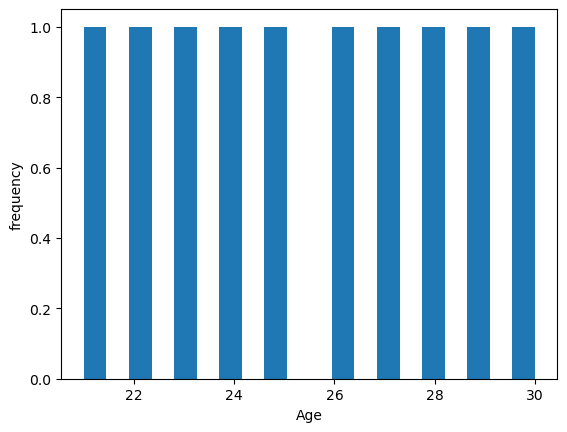

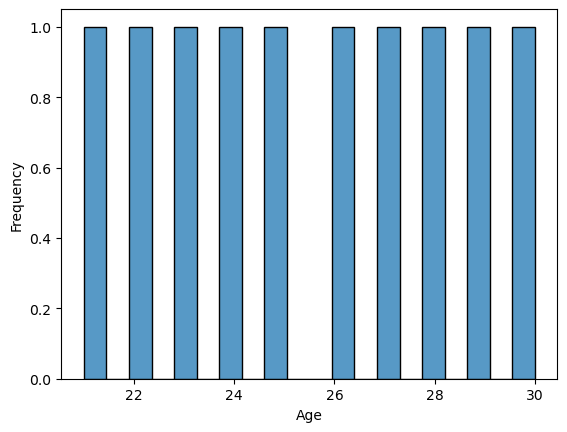

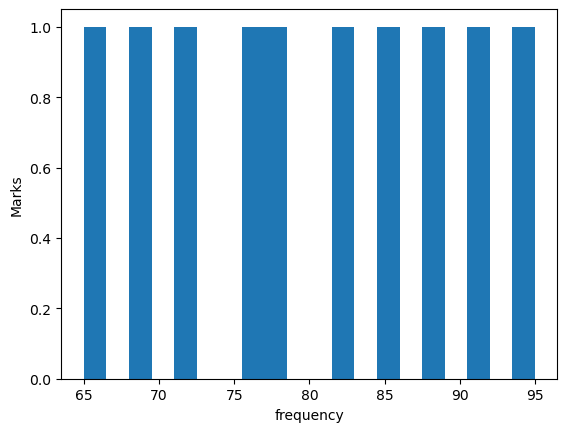

-0.02923554134220031
80.0
73.0
87.25
80.1
65
95


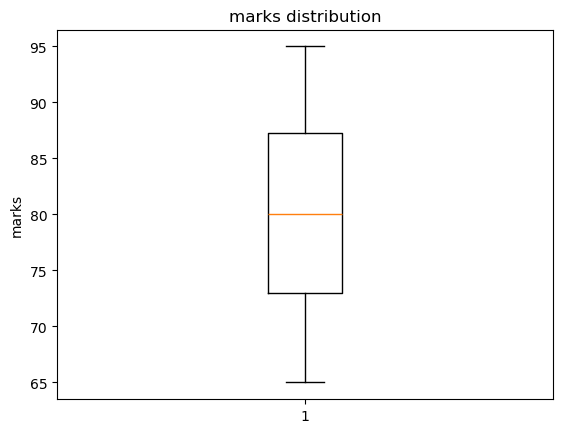

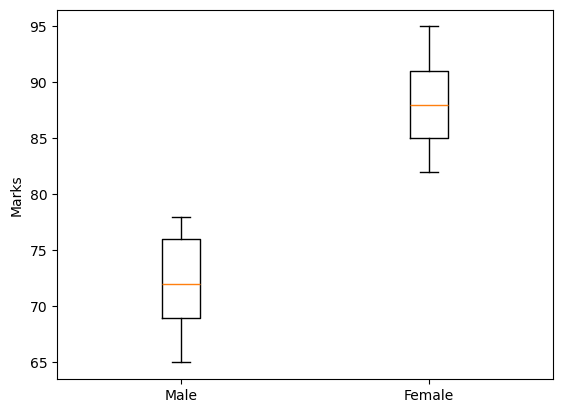

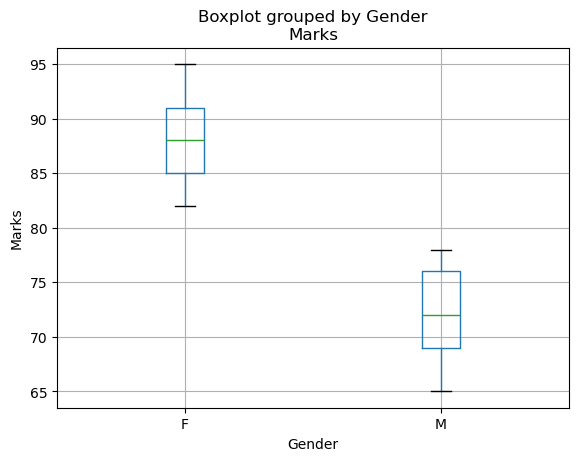

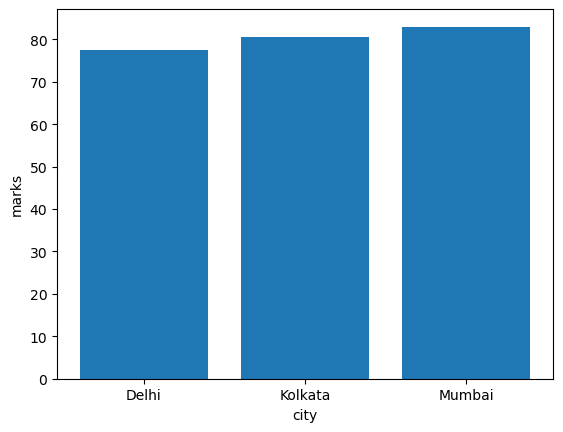

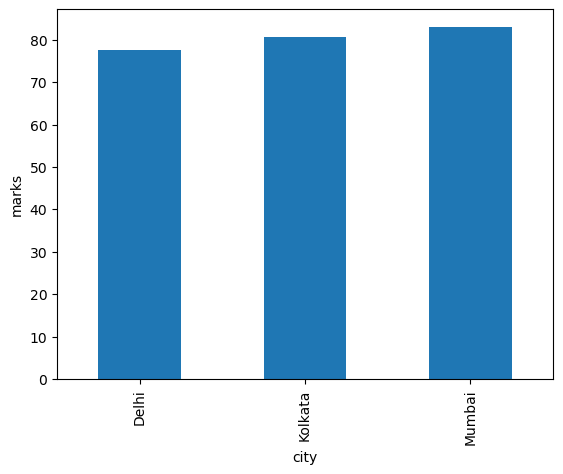

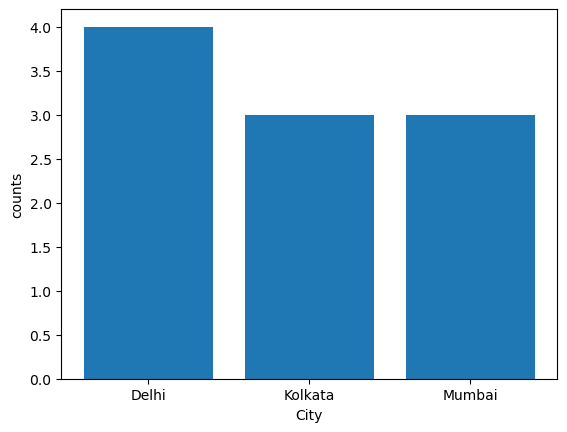

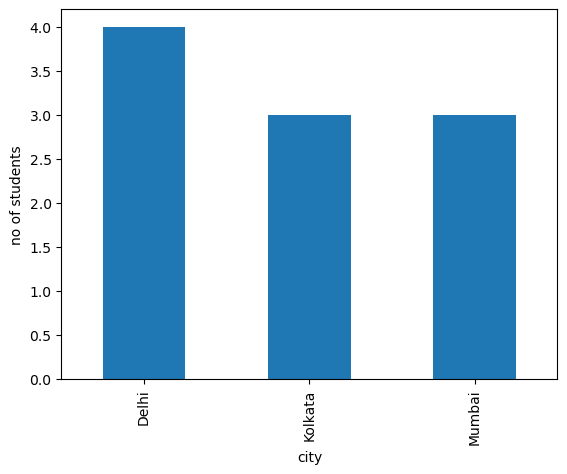

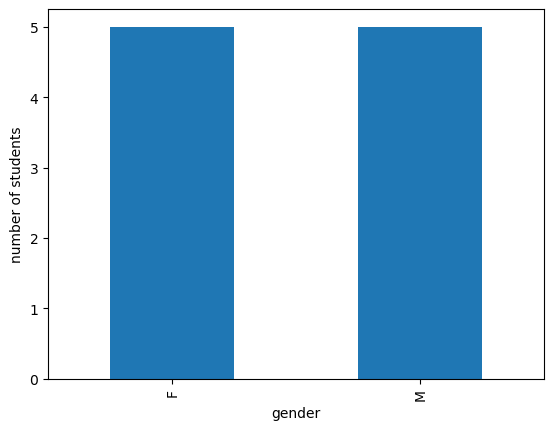

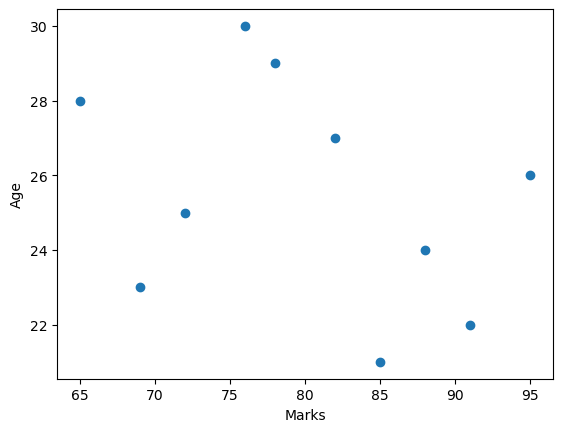

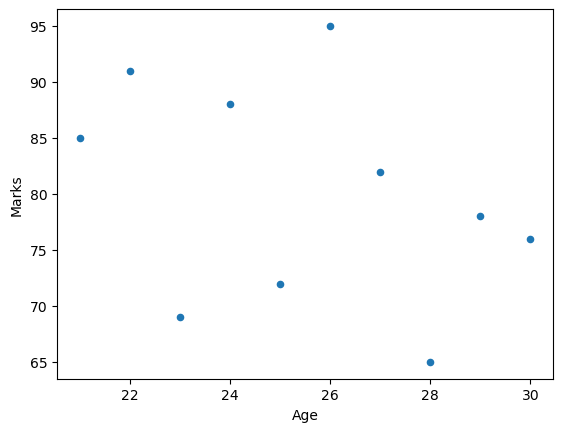

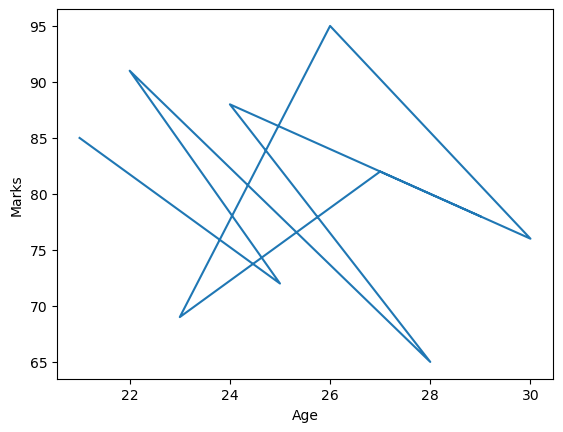

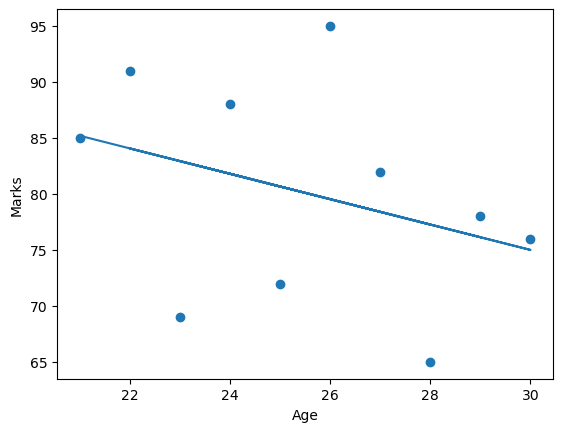

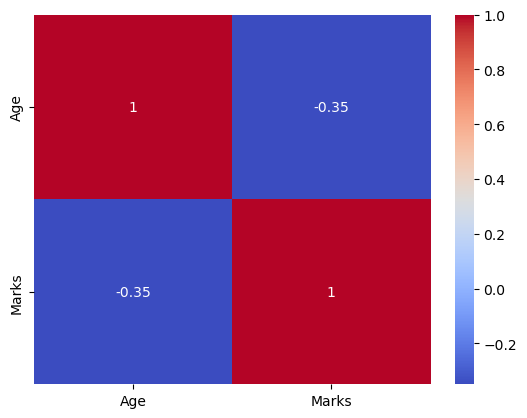

In [59]:
# 🔴 LEVEL 13 — Visualization
# Now use Matplotlib/Seaborn.
# 81. Histogram of Age.
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sn
plt.hist(df["Age"],bins=20)
plt.xlabel("Age")
plt.ylabel("frequency")
plt.show()
sn.histplot(data=df,x="Age",bins=20)
plt.xlabel("Age")
plt.ylabel("Frequency")
plt.show()
# 82. Histogram of Marks.
df
df
plt.hist(df["Marks"],bins=20)
plt.xlabel("frequency")
plt.ylabel("Marks")
plt.show()
# 83. Box plot of Marks.
plt.boxplot(df["Marks"])
plt.ylabel("marks")
plt.title("marks distribution")
print(df["Marks"].skew())
print(df["Marks"].median())
print(df["Marks"].quantile(.25))
print(df["Marks"].quantile(.75))
print(df["Marks"].mean())
print(df["Marks"].min())
print(df["Marks"].max())
plt.show()
# 84. Box plot of Marks by Gender.
plt.boxplot([df[df["Gender"]=="M"]["Marks"],df[df["Gender"]=="F"]["Marks"]])
plt.xticks([1,2],["Male","Female"])
plt.ylabel("Marks")
plt.show()
df.boxplot(column="Marks",by="Gender")
plt.ylabel("Marks")
plt.xlabel("Gender")
plt.show()
# 85. Bar chart of average marks by City.
average_marks=df.groupby("City")["Marks"].agg("mean")
plt.bar(average_marks.index,average_marks.values)
plt.xlabel("city")
plt.ylabel("marks")
plt.show()
average_marks.plot(kind="bar")
plt.xlabel("city")
plt.ylabel("marks")
plt.show()
# 86. Count plot of students by City.
counts=df.groupby("City")["Marks"].count()
plt.bar(counts.index,counts.values)
plt.xlabel("City")
plt.ylabel("counts")
plt.show()
counts.plot(kind="bar")
plt.xlabel("city")
plt.ylabel("no of students")
plt.show()

# 87. Count plot of students by Gender.
counts=df.groupby("Gender")["Name"].count()
counts.plot(kind="bar")
plt.xlabel("gender")
plt.ylabel("number of students")
plt.show()
# 88. Scatter plot of Age vs Marks.
plt.scatter(df["Marks"],df["Age"])
plt.ylabel("Age")
plt.xlabel("Marks")
plt.show()
df.plot.scatter(x="Age",y="Marks")
plt.show()
# 89. Add a trend/regression line to Age vs Marks.
plt.plot(df["Age"],df["Marks"])
plt.xlabel("Age")
plt.ylabel("Marks")
plt.show()
x=df["Age"]
y=df["Marks"]
m,c=np.polyfit(x,y,1)
plt.plot(x,m*x+c)
plt.scatter(x,y)
plt.xlabel("Age")
plt.ylabel("Marks")
plt.show()
# 90. Create a heatmap of numerical correlations.
import seaborn as sns
numerical_data=df.select_dtypes(include="number")
corr=numerical_data.corr()
sns.heatmap(corr,annot=True,cmap="coolwarm")
plt.show()


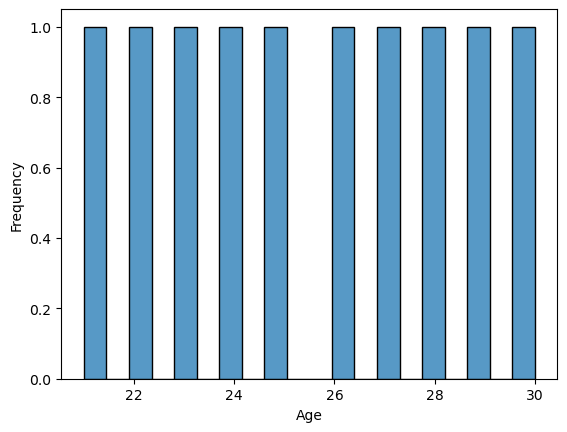

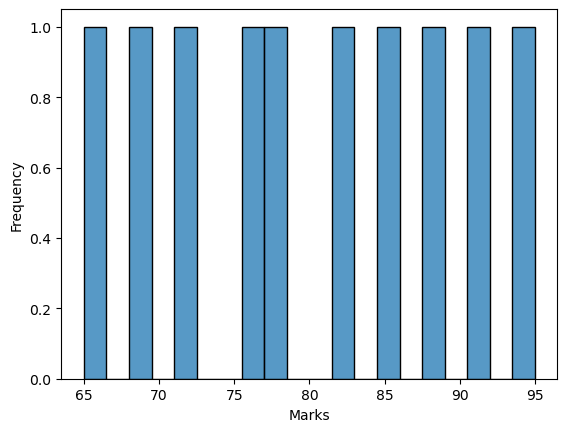

-0.02923554134220031


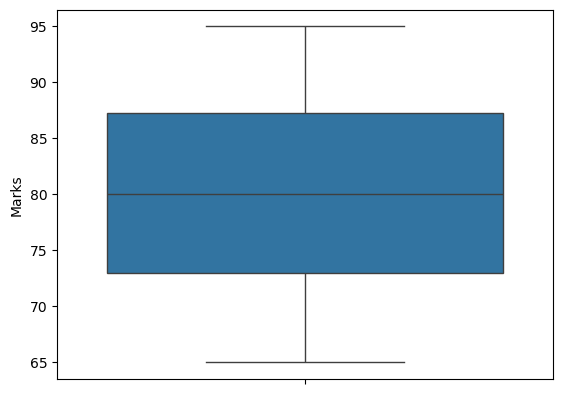

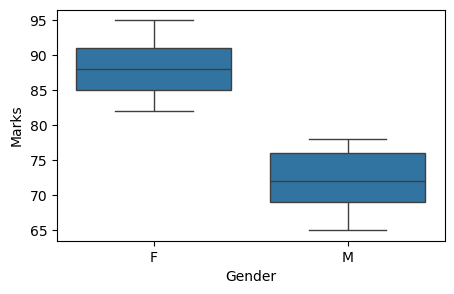

City
Delhi      77.500000
Kolkata    80.666667
Mumbai     83.000000
Name: Marks, dtype: float64


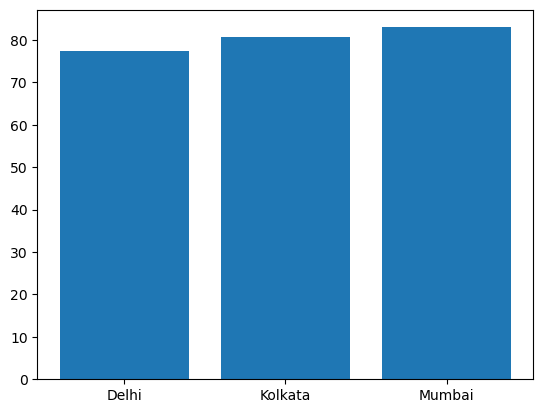

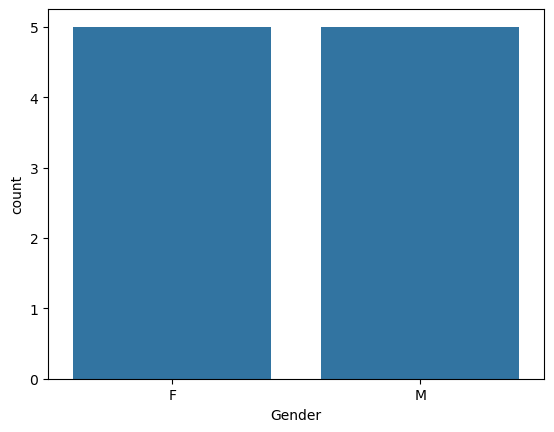

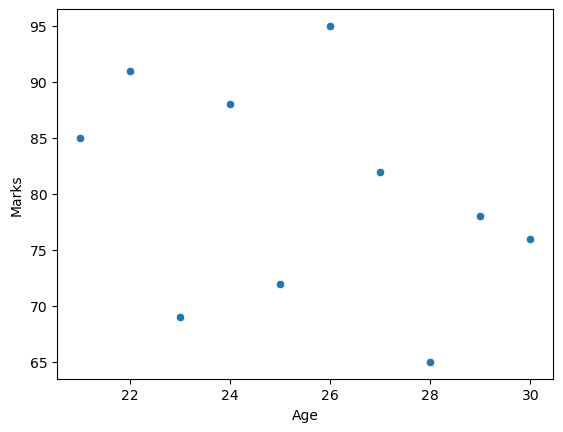

<Figure size 500x300 with 0 Axes>

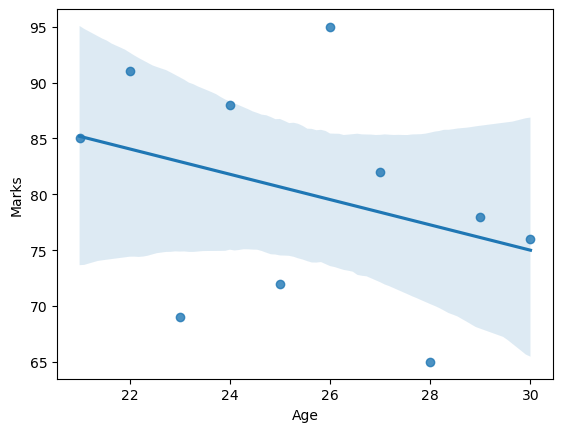

In [57]:

# visualisations using seaborns 
1.
sn.histplot(data=df,x="Age",bins=20)
plt.xlabel("Age")
plt.ylabel("Frequency")
plt.show()

2.
sn.histplot(data=df,x="Marks",bins=20)
plt.xlabel("Marks")
plt.ylabel("Frequency")
plt.show()
3.
sn.boxplot(data=df,y="Marks")
print(df["Marks"].skew())
plt.show()
plt.figure(figsize=(5,3))
4.
sn.boxplot(data=df,x="Gender",y="Marks")
plt.xlabel("Gender")
plt.ylabel("Marks")
plt.show()
5.
average_marks=df.groupby("City")["Marks"].mean()
print(average_marks)
type(average_marks)
# sn.barplot(average_marks,x="City",y="Marks")
# plt.show()
plt.bar(average_marks.index,average_marks.values)
plt.show()
6.
sn.countplot(data=df,x="Gender")
plt.show()
7.
sn.scatterplot(data=df,x="Age",y="Marks")
plt.figure(figsize=(5,3))
plt.show()
8.
sn.regplot(data=df, x="Age", y="Marks")
plt.show()